# PayGuard: Fraud Detection Feasibility (Part A)

**Question:** can ML flag fraudulent card transactions well enough to be worth deploying, and what would production need?

**Short answer (details below):** yes, it is viable. On a *time-ordered* hold-out, both logistic regression and XGBoost are
far above the baseline (PR-AUC about 0.69 and 0.74 vs 0.001). At a cost-chosen threshold, XGBoost catches about 73% of test fraud at
about 68% precision and cuts fraud-plus-review cost by about 60% vs. no model. XGBoost's lead over logistic regression is *not*
statistically clear on this data: 2 days, about 50 test frauds. These numbers are a feasibility signal, not a production forecast.

**Notebook outline**
1. Setup and data loading (works in Colab or locally)
2. Data checks: imbalance, duplicates, time range
3. Evaluation design: what could invalidate the results
4. Models: prevalence baseline, logistic regression, XGBoost
5. Metric comparison with bootstrap confidence intervals
6. Choosing an operating threshold from a cost model
7. Real-time inference: what changes
8. Limitations and what was cut

## 1. Setup
Runs top to bottom in Google Colab. The data loader tries, in order:
a local `data/creditcard.csv`, then `kagglehub` (needs a Kaggle login in Colab), then a manual file upload.

In [1]:
import importlib.util, subprocess, sys
for pkg in ["xgboost", "kagglehub"]:          # both are preinstalled on Colab; this is a safety net
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix)
from xgboost import XGBClassifier

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", "{:.4f}".format)

In [3]:
def load_data():
    """Find creditcard.csv locally, else download via kagglehub, else ask for an upload (Colab)."""
    for path in ["data/creditcard.csv", "../data/creditcard.csv", "creditcard.csv"]:
        if os.path.exists(path):
            return pd.read_csv(path)
    try:
        import kagglehub
        folder = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        return pd.read_csv(os.path.join(folder, "creditcard.csv"))
    except Exception as e:
        print("kagglehub download failed:", e)
    from google.colab import files  # only available in Colab
    uploaded = files.upload()
    return pd.read_csv(next(iter(uploaded)))

raw = load_data()
print(raw.shape)

(284807, 31)


## 2. Data checks

In [4]:
print("Fraud rate: {:.3%}  ({} frauds out of {:,})".format(raw["Class"].mean(), raw["Class"].sum(), len(raw)))
print("Missing values:", raw.isna().sum().sum())
print("Exact duplicate rows:", raw.duplicated().sum(),
      "| of which fraud:", raw[raw["Class"] == 1].duplicated().sum())
print("Time span: {:.1f} hours".format(raw["Time"].max() / 3600))

Fraud rate: 0.173%  (492 frauds out of 284,807)
Missing values: 0


Exact duplicate rows: 1081 | of which fraud: 19
Time span: 48.0 hours


**Duplicates.** About 1,081 rows are exact copies of another row (19 of them fraud). If a row and its copy land on
opposite sides of the split, the model is tested on something it has already seen. I drop exact duplicates before
splitting. In production, you would ask PayGuard whether these are real repeated transactions or ingestion artefacts.

In [5]:
df = raw.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
print(df.shape, "frauds:", df["Class"].sum())

(283726, 31) frauds: 473


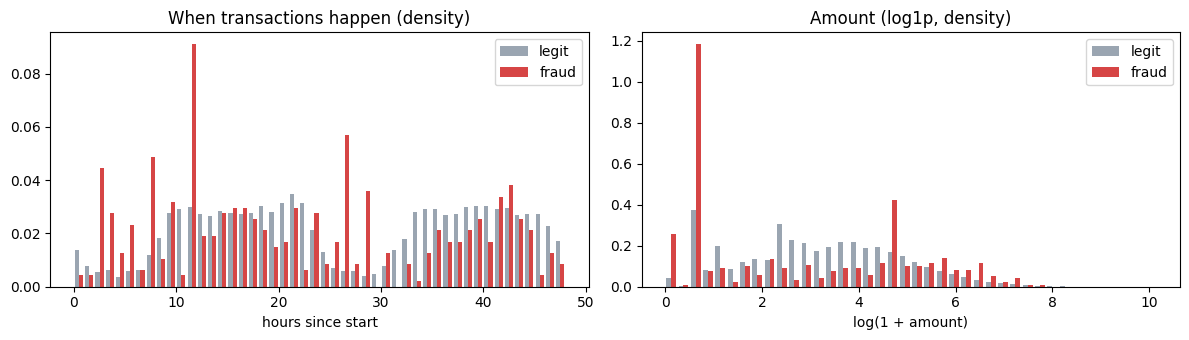

          mean     50%        max
Class                            
0      88.4136 22.0000 25691.1600
1     123.8719  9.8200  2125.8700


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hours = df["Time"] / 3600
axes[0].hist([hours[df.Class == 0], hours[df.Class == 1]], bins=48, density=True,
             label=["legit", "fraud"], color=["#9aa5b1", "#d64545"])
axes[0].set(title="When transactions happen (density)", xlabel="hours since start"); axes[0].legend()
axes[1].hist([np.log1p(df.Amount[df.Class == 0]), np.log1p(df.Amount[df.Class == 1])], bins=40,
             density=True, label=["legit", "fraud"], color=["#9aa5b1", "#d64545"])
axes[1].set(title="Amount (log1p, density)", xlabel="log(1 + amount)"); axes[1].legend()
plt.tight_layout(); plt.show()

print(df.groupby("Class")["Amount"].describe()[["mean", "50%", "max"]])

Fraud is spread across both days and is not concentrated in large amounts: the median fraud is about 9 vs about 22 for
legitimate transactions. This matters for the cost model later, because missing a small fraud costs little.

## 3. Evaluation design: what could invalidate the results

| Risk | What goes wrong | What I do |
|---|---|---|
| **Random split** | Training on transactions from *after* the test ones lets the model learn about fraud patterns it could not know about yet. Scores look better than they will in production. | **Time-ordered split**: first 70% of time for training, next 15% for validation, last 15% for test. |
| **Preprocessing leakage** | Fitting the scaler (or SMOTE) on all the data leaks test statistics into training. | Scaling sits inside an sklearn `Pipeline` fit on train only. No resampling (class weights instead). |
| **Threshold tuned on test** | Picking the threshold on the same data you report on makes the result look better than it is. | Threshold and early stopping use **validation** only. Test is touched once, at the end. |
| **Duplicates across splits** | The model is tested on rows it memorised. | Exact duplicates are dropped (above). |
| **Accuracy / ROC-AUC** | With 0.17% fraud, "always legit" scores 99.8% accuracy. ROC-AUC is dominated by the huge number of true negatives and looks great for weak models. | Primary metric **PR-AUC (average precision)**, plus recall at fixed precision and business cost. |
| **Small test set** | About 50 test frauds, so one extra catch moves recall by 2 points. | **Bootstrap 95% CIs** on every test metric. |
| **`Time` as a feature** | It is "seconds since the dataset started", which doesn't exist in production. | Excluded. (Hour of day could be derived, but the start timezone is unknown and 2 days can't validate it.) |

In [7]:
n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train, val, test = df.iloc[:train_end], df.iloc[train_end:val_end], df.iloc[val_end:]

summary = pd.DataFrame({
    "rows": [len(s) for s in (train, val, test)],
    "frauds": [s.Class.sum() for s in (train, val, test)],
    "fraud_rate_%": [100 * s.Class.mean() for s in (train, val, test)],
    "hours": [f"{s.Time.min()/3600:.1f} to {s.Time.max()/3600:.1f}" for s in (train, val, test)],
}, index=["train", "validation", "test"])
summary

,rows,frauds,fraud_rate_%,hours
train,198608,366,0.1843,0.0 to 36.9
validation,42559,55,0.1292,36.9 to 42.0
test,42559,52,0.1222,42.0 to 48.0


In [8]:
V_COLS = [f"V{i}" for i in range(1, 29)]

def make_features(d):
    """Features available at authorisation time. V1-V28 are PCA components; Amount is log-transformed (heavy right tail)."""
    X = d[V_COLS].copy()
    X["log_amount"] = np.log1p(d["Amount"])
    return X

X_train, y_train = make_features(train), train["Class"].values
X_val, y_val = make_features(val), val["Class"].values
X_test, y_test = make_features(test), test["Class"].values

## 4. Models

1. **Prevalence baseline** (`DummyClassifier`): predicts the base rate. It sets the floor: its PR-AUC is roughly the fraud rate.
2. **Logistic regression** with `class_weight="balanced"`: the simple, explainable baseline a regulator would understand.
3. **XGBoost**: gradient-boosted trees capture non-linear interactions between the PCA components.
   Moderate fixed settings, early stopping on validation PR-AUC. No hyperparameter search (out of scope by design).

**Why no SMOTE or deep learning?** Class weighting achieves the same rebalancing without synthetic points or leakage risk.
On about 30 tabular, already-PCA'd features, boosted trees are the established strong choice. A neural network would add
complexity without a reason to expect a gain.

In [9]:
models = {}

models["baseline (prevalence)"] = DummyClassifier(strategy="prior").fit(X_train, y_train)

models["logistic regression"] = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
).fit(X_train, y_train)

xgb = XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
    eval_metric="aucpr", early_stopping_rounds=100, random_state=SEED, n_jobs=-1,
)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
models["xgboost"] = xgb
print("XGBoost best iteration:", xgb.best_iteration)

XGBoost best iteration: 155


Note: XGBoost is trained **without** `scale_pos_weight`. Up-weighting fraud tends to leave the ranking (PR-AUC) about the
same but distorts the probabilities, and section 6 uses those probabilities in a cost calculation. Logistic regression
with balanced weights produces inflated probabilities, which is fine for ranking but not for expected-cost decisions.

## 5. Comparison
Metrics:
- **PR-AUC (average precision)**, primary: how well the model ranks fraud above legit, focused on the positive class.
- **Recall @ 80% precision / @ 50% precision**: "if we accept that 1 in 5 (or 1 in 2) alerts is a false alarm, what share of fraud do we catch?"
- **ROC-AUC**: reported only to show how flattering it is here.

Confidence intervals come from 1,000 bootstrap resamples of the test set.

In [10]:
def recall_at_precision(y, p, min_precision):
    prec, rec, _ = precision_recall_curve(y, p)
    ok = prec >= min_precision
    return rec[ok].max() if ok.any() else 0.0

METRICS = {
    "PR-AUC": average_precision_score,
    "ROC-AUC": roc_auc_score,
    "Recall@P80": lambda y, p: recall_at_precision(y, p, 0.80),
    "Recall@P50": lambda y, p: recall_at_precision(y, p, 0.50),
}

def bootstrap_ci(y, p, fn, n_boot=1000):
    idx = np.arange(len(y))
    stats = []
    for _ in range(n_boot):
        s = rng.choice(idx, size=len(idx), replace=True)
        if y[s].sum() == 0:
            continue
        stats.append(fn(y[s], p[s]))
    return np.percentile(stats, [2.5, 97.5])

scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
val_scores = {name: m.predict_proba(X_val)[:, 1] for name, m in models.items()}

rows = []
for name, p in scores.items():
    row = {"model": name, "val PR-AUC": average_precision_score(y_val, val_scores[name])}
    for metric, fn in METRICS.items():
        lo, hi = bootstrap_ci(y_test, p, fn)
        row[f"test {metric}"] = f"{fn(y_test, p):.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(row)
results = pd.DataFrame(rows).set_index("model")
results

,val PR-AUC,test PR-AUC,test ROC-AUC,test Recall@P80,test Recall@P50
model,,,,,
baseline (prevalence),0.0013,"0.001 [0.001, 0.002]","0.500 [0.500, 0.500]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]"
logistic regression,0.8123,"0.691 [0.554, 0.841]","0.977 [0.958, 0.992]","0.692 [0.553, 0.833]","0.750 [0.625, 0.867]"
xgboost,0.8676,"0.738 [0.613, 0.849]","0.978 [0.960, 0.992]","0.712 [0.545, 0.850]","0.750 [0.605, 0.861]"


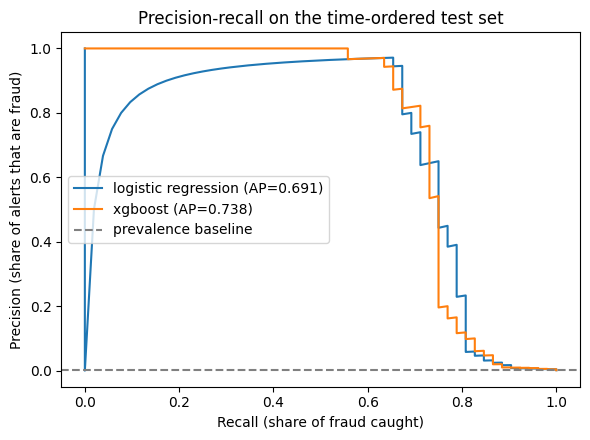

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, p in scores.items():
    if name.startswith("baseline"):
        continue
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", c="grey", label="prevalence baseline")
ax.set(xlabel="Recall (share of fraud caught)", ylabel="Precision (share of alerts that are fraud)",
       title="Precision-recall on the time-ordered test set")
ax.legend(); plt.tight_layout(); plt.show()

**Is XGBoost really better, or is it noise?** The two sets of intervals above overlap, so I compare them directly: on each
bootstrap resample, compute XGBoost's PR-AUC minus logistic regression's PR-AUC *on the same rows*. If the 95% interval
of that difference excludes 0, the gap is unlikely to be noise.

In [12]:
def paired_bootstrap_diff(y, p_a, p_b, fn=average_precision_score, n_boot=1000):
    diffs = []
    for _ in range(n_boot):
        s = rng.choice(len(y), size=len(y), replace=True)
        if y[s].sum() == 0:
            continue
        diffs.append(fn(y[s], p_a[s]) - fn(y[s], p_b[s]))
    diffs = np.array(diffs)
    return diffs.mean(), np.percentile(diffs, [2.5, 97.5]), (diffs > 0).mean()

mean_d, (lo_d, hi_d), share_pos = paired_bootstrap_diff(y_test, scores["xgboost"], scores["logistic regression"])
print(f"PR-AUC(XGBoost) - PR-AUC(LogReg): {mean_d:+.3f}  95% CI [{lo_d:+.3f}, {hi_d:+.3f}]  "
      f"XGBoost ahead in {share_pos:.0%} of resamples")

PR-AUC(XGBoost) - PR-AUC(LogReg): +0.037  95% CI [-0.034, +0.134]  XGBoost ahead in 70% of resamples


**Reading the comparison**
- ROC-AUC is high for *both* real models and hardly separates them. This is why it isn't the headline metric here.
- PR-AUC separates them more: XGBoost is ahead on validation (0.87 vs 0.81) and test (0.74 vs 0.69).
- The confidence intervals are wide. With about 50 test frauds, the honest conclusion is "both models are far above the
  baseline; XGBoost is ahead on point estimates (in about 70% of paired resamples), but the paired 95% interval includes zero",
  so the data does not prove XGBoost is better.
- **Practical implication:** logistic regression is a credible fallback. It is simpler, explainable to a regulator and
  cheap to serve. For a first production release, XGBoost's gain should be confirmed on more weeks of data before
  accepting its extra operational cost.

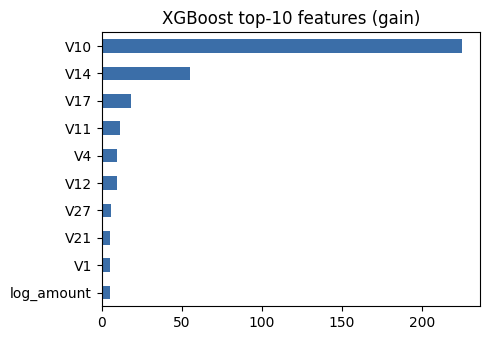

In [13]:
# Which features drive XGBoost? (Anonymised PCA components, so interpretation is limited; this is a sanity check.)
imp = pd.Series(xgb.get_booster().get_score(importance_type="gain")).sort_values(ascending=False).head(10)
imp.plot.barh(figsize=(5, 3.5), color="#3b6ea8", title="XGBoost top-10 features (gain)").invert_yaxis()
plt.tight_layout(); plt.show()

## 6. Choosing the operating threshold

A score is only useful once we decide what to *do* at each score. The threshold follows from what each error costs PayGuard.

| Error | What happens | Assumed cost |
|---|---|---|
| **False negative** (missed fraud) | PayGuard or the issuer absorbs the loss via chargeback, plus handling fees and scheme penalties if fraud rates get too high. | `Amount + $15` chargeback/handling fee |
| **False positive** (legit flagged) | Analyst review or a step-up check (OTP), customer friction, some abandoned purchases, and in emerging markets a real risk the customer goes back to cash or a competitor. | `$5` flat per alert |

These cost values are **assumptions for illustration**; PayGuard's finance and ops teams would supply the real numbers.
They are parameters below, and a sensitivity check follows.

Two decision rules, both **chosen on validation** and then applied once to test:
1. **Single global threshold**: flag if `score > t`, with `t` chosen to minimise total cost on validation.
2. **Amount-aware rule**: flag if `p(fraud) * (Amount + fee) > FP cost`, i.e. only when the expected loss exceeds the cost of
   checking. This needs roughly calibrated probabilities, which is why XGBoost was trained without reweighting.
   A calibration check is below.

In [14]:
FN_FEE, FP_COST = 15.0, 5.0

def total_cost(y, flagged, amount, fn_fee=FN_FEE, fp_cost=FP_COST):
    fn = (y == 1) & ~flagged
    fp = (y == 0) & flagged
    return (amount[fn] + fn_fee).sum() + fp_cost * fp.sum()

def best_global_threshold(y, p, amount, **kw):
    grid = np.unique(np.quantile(p, np.linspace(0.95, 1.0, 2001)))
    costs = [total_cost(y, p >= t, amount, **kw) for t in grid]
    return grid[int(np.argmin(costs))]

def amount_aware_flags(p, amount, fn_fee=FN_FEE, fp_cost=FP_COST):
    return p * (amount + fn_fee) > fp_cost

# Alerts/day = alert RATE x average daily volume. (Scaling the 6-hour test window up to 24 h would
# overstate it: evening hours are busier than the 2-day average.)
TX_PER_DAY = len(df) / (df["Time"].max() / 86400)

def alerts_per_day(n_flagged, n_rows):
    return round(n_flagged / n_rows * TX_PER_DAY)

def describe_policy(y, flagged, amount):
    tn, fp, fn, tp = confusion_matrix(y, flagged, labels=[0, 1]).ravel()
    return {
        "alerts/day": alerts_per_day(tp + fp, len(y)),
        "fraud caught": f"{tp}/{tp + fn}",
        "precision": tp / max(tp + fp, 1),
        "$ fraud caught": amount[(y == 1) & flagged].sum(),
        "$ fraud missed": amount[(y == 1) & ~flagged].sum(),
        "total cost $": total_cost(y, flagged, amount),
    }

amt_val, amt_test = val["Amount"].values, test["Amount"].values
p_val, p_test = val_scores["xgboost"], scores["xgboost"]

t_star = best_global_threshold(y_val, p_val, amt_val)
policies = {
    "flag nothing": np.zeros_like(y_test, dtype=bool),
    "default 0.5": p_test >= 0.5,
    f"cost-optimal global (t={t_star:.3f})": p_test >= t_star,
    "amount-aware rule": amount_aware_flags(p_test, amt_test),
}
print(f"Average volume: {TX_PER_DAY:,.0f} transactions/day")
pd.DataFrame({k: describe_policy(y_test, f, amt_test) for k, f in policies.items()}).T

Average volume: 141,870 transactions/day


,alerts/day,fraud caught,precision,$ fraud caught,$ fraud missed,total cost $
flag nothing,0,0/52,0.0000,0.0000,6168.8800,6948.8800
default 0.5,130,34/52,0.8718,3457.5500,2711.3300,3006.3300
cost-optimal global (t=0.117),187,38/52,0.6786,3756.5800,2412.3000,2712.3000
amount-aware rule,390,38/52,0.3248,3756.5800,2412.3000,3017.3000


In [15]:
# Calibration check: do predicted probabilities match observed fraud rates? (validation set, top-scored bins)
bins = pd.qcut(p_val, q=[0, .99, .995, .999, .9995, 1.0], duplicates="drop")
calib = pd.DataFrame({"p": p_val, "y": y_val}).groupby(bins, observed=True).agg(
    mean_predicted=("p", "mean"), observed_rate=("y", "mean"), n=("y", "size"))
calib

,mean_predicted,observed_rate,n
"(-0.00099511, 0.0043]",0.0001,0.0001,42133
"(0.0043, 0.0123]",0.0070,0.0094,213
"(0.0123, 0.498]",0.0544,0.0471,170
"(0.498, 0.937]",0.8564,0.9048,21
"(0.937, 0.988]",0.9681,1.0000,22


**Sensitivity.** The chosen threshold depends on the cost assumptions. Below, the false-positive cost varies from $1
(a cheap automated OTP) to $500 (a manual investigation plus a lost customer).

In [16]:
sens = []
for fp_cost in [1, 5, 20, 50, 100, 200, 500]:
    t = best_global_threshold(y_val, p_val, amt_val, fp_cost=fp_cost)
    flagged = p_test >= t
    tn, fp, fn, tp = confusion_matrix(y_test, flagged, labels=[0, 1]).ravel()
    sens.append({"FP cost $": fp_cost, "threshold": t, "recall": tp / (tp + fn),
                 "precision": tp / max(tp + fp, 1), "alerts/day": alerts_per_day(tp + fp, len(y_test))})
pd.DataFrame(sens).set_index("FP cost $")

,threshold,recall,precision,alerts/day
FP cost $,,,,
1,0.1171,0.7308,0.6786,187
5,0.1171,0.7308,0.6786,187
20,0.1171,0.7308,0.6786,187
50,0.1171,0.7308,0.6786,187
100,0.1171,0.7308,0.6786,187
200,0.4984,0.6538,0.8718,130
500,0.7437,0.6346,0.9429,117


**What the sensitivity shows.** The chosen threshold barely moves until false positives become very expensive. The reason
is visible in the validation data: one fraud of about $1,000 scores only about 0.15. Catching that single transaction is
worth more than the dozen or so extra false alarms needed to reach it. **The threshold is being set by one transaction**,
a direct symptom of having only 55 validation frauds. In production the threshold would be chosen on several weeks of
labelled data, so that no single case dominates.

**Global threshold vs. the amount-aware rule.** In theory the amount-aware rule is optimal. Here it catches the same fraud
as the global threshold while raising roughly twice as many alerts, so it costs *more*. Probabilities are only roughly
calibrated in the 0.01–0.5 range (see the calibration table), and many high-amount legitimate transactions sit there.
I would not ship it without proper calibration and more data. The simpler global threshold wins for now.

### Recommendation: where I would operate

- **Start at the cost-optimal global threshold (about 0.12 here), not 0.5.** On the test period it catches about 73% of fraud
  at about 68% precision, and cuts total fraud-plus-review cost by about 60% vs. no model. That comes to about 187 alerts/day at this
  transaction volume. 0.5 is an arbitrary default and has nothing to do with PayGuard's economics.
- **Use tiers rather than one yes/no decision:** a very high score means decline and alert the customer; a mid score means
  step-up authentication (OTP or in-app confirmation), which makes a false positive cheap; a low score means approve.
  Step-up is the lever that keeps FP cost near the low end of the sensitivity table.
- **Check against review capacity.** Whatever threshold wins on cost must also fit the number of alerts the ops team can
  work each day. If it doesn't, capacity sets the threshold, and the business needs to know the fraud cost of that constraint.
- **The threshold is not fixed.** Fraud rate and customer behaviour drift, so the threshold should be re-picked on recent
  labelled data on a schedule (e.g. monthly), using the same validation-only procedure.

## 7. Real-time inference: what changes

Card authorisation has to answer in roughly **50–100 ms end to end**, so the model's share is maybe 10–20 ms. That changes the setup in five ways:

**Features**
- Only data that exists **at authorisation time** can be used. The strongest real-world fraud signals are behavioural
  aggregates this dataset has hidden inside the PCA: *transactions on this card in the last 1 h / 24 h, amount vs. the
  card's usual amount, new merchant or device for this customer, distance from the last transaction, time since the last one*.
- These need a **low-latency feature store** (e.g. Redis) updated in streaming (Kafka/Flink). The same feature code must
  run in training (offline, replaying history "as of" each transaction) and serving (online). Otherwise you get
  **training/serving skew**, the most common silent failure in fraud systems.
- Every training feature must be computed **point-in-time**: using only events before that transaction. Otherwise
  future information leaks in, the same problem as the random split.
- `Time` here (seconds since the dataset started) can't be a production feature. The real equivalent would be local hour
  of day or day of week.

**Modelling**
- **Model size and speed:** a few hundred shallow trees score in well under 1 ms on a CPU, so XGBoost fits the budget. A large
  ensemble or a deep sequence model would need justification against that budget.
- **Label delay:** fraud labels arrive days or weeks later, when chargebacks come in. Training data is always a bit stale,
  and the most recent period has unlabelled fraud, so the model must be trained on a window that has had time to mature.
- **Feedback loop:** transactions we block never produce a chargeback label, so we never learn whether they were really
  fraud. The standard fix is to let a tiny random share of mid-score transactions through, or send them to step-up rather
  than blocking, so unbiased labels keep coming in.
- **Fallback:** if the feature store or model times out, the authorisation still has to answer. A simple rule set is the
  safe default; the system must not stall or approve everything silently.
- **Rules and ML together:** hard business rules (sanctioned merchants, velocity caps) run alongside the model. The model
  doesn't replace them.

## 8. Limitations and what I cut

- **Only 2 days of data.** There's no way to test weekly patterns, drift, or how often to retrain. In production I would
  evaluate on several consecutive future windows ("backtesting") rather than one test split.
- **Anonymised PCA features.** I can't engineer the behavioural features that matter most, and I can't explain decisions
  in business terms, which matters for customer disputes and the regulator.
- **About 50 test frauds.** The confidence intervals are the honest result; single numbers overstate precision.
- **Illustrative cost model.** It needs PayGuard's real chargeback, review and churn costs.
- **Cut on purpose:** hyperparameter search, ensembling, SMOTE and neural networks. None of them change the feasibility
  answer, and the brief asked for reasoning over leaderboard gains.
- **Not done but next:** probability calibration (isotonic, fit on validation) if the amount-aware rule goes to production;
  SHAP explanations per alert for the analysts.